# Лабораторная работа 3. Анализ сетевого трафика

## Индивидуальное задание вариант 2

**Выполнили:** М.Р. Осколков, А.Ю. Бердников **Группа:** ИНБс-5301

Задание: Подбор глубины дерева на честном протоколе. В блокноте 02 переберите max_depth
= 5, 10, 15, 20, 30, None по кросс-валидации на KDDTrain+, оцените лучшую модель на KDDTest+.
Сравните с базовым деревом (без ограничения глубины): помогает ли ограничение глубины
обобщению на новые атаки?

In [4]:
# --- Только для Google Colab: раскомментируйте один из вариантов ---

# Вариант А: архив datasets.zip лежит в корне Google Диска (рекомендуется)
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/datasets.zip" -d /content/

# Вариант Б: разовая загрузка архива в сессию Colab
# from google.colab import files
# uploaded = files.upload()  # выберите datasets.zip
# !unzip -q datasets.zip -d /content/

Mounted at /content/drive


In [5]:
import os

DATA_DIR = 'datasets' if os.path.isdir('datasets') else '/content/datasets'

for name in ['ids.csv', 'KDDTrain+.csv', 'KDDTest+.csv']:
    path = os.path.join(DATA_DIR, name)
    assert os.path.isfile(path), (
        f'Файл {name} не найден по пути {path}. '
        'В Colab выполните ячейку «Шаг 0», локально — положите папку datasets рядом с блокнотом.')

print('Датасеты на месте:', sorted(os.listdir(DATA_DIR)))

Датасеты на месте: ['KDDTest+.csv', 'KDDTrain+.csv', 'ids.csv']


In [6]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 2

In [7]:
COLS = ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
        'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
        'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
        'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
        'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
        'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
        'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
        'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
        'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
        'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty']

data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTrain+.csv'), header=None, names=COLS)
print('Размер:', data.shape)
data.head(3)

Размер: (125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [8]:
print('Различных меток:', data['label'].nunique())
print()
print(data['label'].value_counts().to_string())

Различных меток: 23

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2


In [9]:
ATTACK_CATEGORY = {
    'normal': 'normal',
    # dos — отказ в обслуживании
    'neptune': 'dos', 'smurf': 'dos', 'back': 'dos', 'teardrop': 'dos',
    'pod': 'dos', 'land': 'dos', 'apache2': 'dos', 'udpstorm': 'dos',
    'processtable': 'dos', 'mailbomb': 'dos', 'worm': 'dos',
    # probe — разведка и сканирование
    'satan': 'probe', 'ipsweep': 'probe', 'portsweep': 'probe',
    'nmap': 'probe', 'mscan': 'probe', 'saint': 'probe',
    # r2l — неавторизованный доступ с удалённой машины
    'warezclient': 'r2l', 'guess_passwd': 'r2l', 'warezmaster': 'r2l',
    'imap': 'r2l', 'ftp_write': 'r2l', 'multihop': 'r2l', 'phf': 'r2l',
    'spy': 'r2l', 'httptunnel': 'r2l', 'snmpguess': 'r2l',
    'snmpgetattack': 'r2l', 'named': 'r2l', 'sendmail': 'r2l',
    'xlock': 'r2l', 'xsnoop': 'r2l',
    # u2r — повышение привилегий до root
    'buffer_overflow': 'u2r', 'rootkit': 'u2r', 'loadmodule': 'u2r',
    'perl': 'u2r', 'ps': 'u2r', 'sqlattack': 'u2r', 'xterm': 'u2r',
}

data['category'] = data['label'].map(ATTACK_CATEGORY)
assert data['category'].notna().all(), 'Есть метки без категории — проверьте словарь'

cat_counts = data['category'].value_counts()
print(cat_counts.to_string())
print()
print('Доли: ' + ', '.join(f'{k} {v / len(data):.1%}' for k, v in cat_counts.items()))

category
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52

Доли: normal 53.5%, dos 36.5%, probe 9.3%, r2l 0.8%, u2r 0.0%


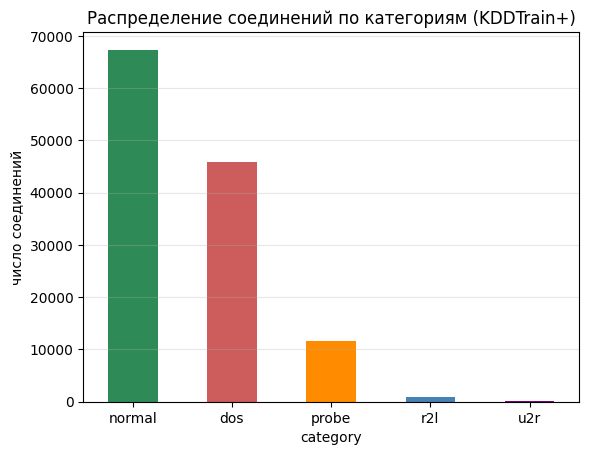

In [10]:
cat_counts.plot.bar(color=['seagreen', 'indianred', 'darkorange', 'steelblue', 'purple'])
plt.title('Распределение соединений по категориям (KDDTrain+)')
plt.ylabel('число соединений')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [11]:
X = data.drop(columns=['label', 'difficulty', 'category'])
y = data['category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f'train: {X_train.shape[0]} соединений, test: {X_test.shape[0]} соединений')
print()
print('train:', y_train.value_counts().to_dict())
print('test: ', y_test.value_counts().to_dict())

train: 100778 соединений, test: 25195 соединений

train: {'normal': 53874, 'dos': 36741, 'probe': 9325, 'r2l': 796, 'u2r': 42}
test:  {'normal': 13469, 'dos': 9186, 'probe': 2331, 'r2l': 199, 'u2r': 10}


In [12]:
cat_cols = ['protocol_type', 'service', 'flag']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', MinMaxScaler(), num_cols),
])

In [13]:
model_knn = make_pipeline(preprocess, KNeighborsClassifier(n_neighbors=5, n_jobs=-1))

t0 = time.time()
model_knn.fit(X_train, y_train)
t1 = time.time()
y_pred = model_knn.predict(X_test)
t2 = time.time()

print(f'Обучение: {t1 - t0:.1f} с, прогноз на {len(X_test)} соединений: {t2 - t1:.1f} с')
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print()
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

Обучение: 0.2 с, прогноз на 25195 соединений: 13.3 с
Accuracy: 0.994

              precision    recall  f1-score   support

         dos      0.995     0.999     0.997      9186
      normal      0.996     0.996     0.996     13469
       probe      0.992     0.976     0.984      2331
         r2l      0.929     0.915     0.922       199
         u2r      0.600     0.300     0.400        10

    accuracy                          0.994     25195
   macro avg      0.902     0.837     0.860     25195
weighted avg      0.994     0.994     0.994     25195



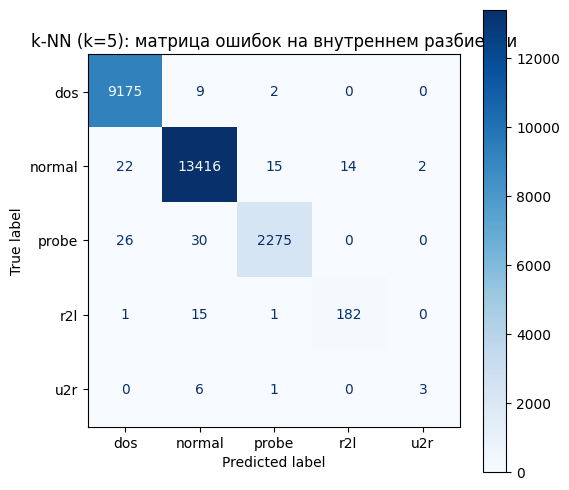

In [14]:
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap='Blues')
plt.title('k-NN (k=5): матрица ошибок на внутреннем разбиении')
plt.grid(False)
plt.show()

In [15]:
model_tree = make_pipeline(preprocess, DecisionTreeClassifier(random_state=RANDOM_STATE))

t0 = time.time()
model_tree.fit(X_train, y_train)
y_pred_tree = model_tree.predict(X_test)
print(f'Обучение: {time.time() - t0:.1f} с')
print(f'Accuracy: {accuracy_score(y_test, y_pred_tree):.3f}')
print()
print(classification_report(y_test, y_pred_tree, digits=3, zero_division=0))

Обучение: 1.1 с
Accuracy: 0.997

              precision    recall  f1-score   support

         dos      0.999     0.999     0.999      9186
      normal      0.998     0.998     0.998     13469
       probe      0.993     0.995     0.994      2331
         r2l      0.974     0.950     0.962       199
         u2r      0.429     0.600     0.500        10

    accuracy                          0.997     25195
   macro avg      0.879     0.908     0.891     25195
weighted avg      0.998     0.997     0.998     25195



In [16]:
test_data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTest+.csv'), header=None, names=COLS)
test_data['category'] = test_data['label'].map(ATTACK_CATEGORY)
assert test_data['category'].notna().all()

new_attacks = sorted(set(test_data['label']) - set(data['label']))
print(f'Типов меток в тесте: {test_data["label"].nunique()}, из них новых (нет в train): {len(new_attacks)}')
print('Новые типы атак:', ', '.join(new_attacks))
print()
print(test_data['category'].value_counts().to_string())

Типов меток в тесте: 38, из них новых (нет в train): 17
Новые типы атак: apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm

category
normal    9710
dos       7460
r2l       2885
probe     2421
u2r         67


In [17]:
# Переобучаем обе модели на ВСЁМ тренировочном наборе и проверяем на KDDTest+
X_full, y_full = X, y
X_test_real, y_test_real = (test_data.drop(columns=['label', 'difficulty', 'category']),
                            test_data['category'])

models_real = {}
for name, make_model in [('k-NN (k=5)', lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
                         ('Дерево решений', lambda: DecisionTreeClassifier(random_state=RANDOM_STATE))]:
    model = make_pipeline(preprocess, make_model())
    t0 = time.time()
    model.fit(X_full, y_full)
    acc = model.score(X_test_real, y_test_real)
    models_real[name] = model
    print(f'{name}: обучение {time.time() - t0:.1f} с, accuracy на KDDTest+ = {acc:.3f}')

k-NN (k=5): обучение 15.4 с, accuracy на KDDTest+ = 0.738
Дерево решений: обучение 1.4 с, accuracy на KDDTest+ = 0.769


In [18]:
# Подробный отчёт для лучшей модели (дерево решений)
y_pred_real = models_real['Дерево решений'].predict(X_test_real)
print(classification_report(y_test_real, y_pred_real, digits=3, zero_division=0))

              precision    recall  f1-score   support

         dos      0.954     0.828     0.886      7460
      normal      0.700     0.966     0.811      9710
       probe      0.642     0.634     0.638      2421
         r2l      0.941     0.083     0.152      2885
         u2r      0.571     0.179     0.273        67

    accuracy                          0.769     22543
   macro avg      0.762     0.538     0.552     22543
weighted avg      0.808     0.769     0.732     22543



In [19]:
#Индивидуальное задание
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score

param_grid = {'decisiontreeclassifier__max_depth': [5, 10, 15, 20, 30, None]}

grid = GridSearchCV(
    make_pipeline(preprocess, DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X, y)   # X, y — полный KDDTrain+ из шага 3

print('Лучшие параметры:', grid.best_params_)
print(f'Accuracy на кросс-валидации: {grid.best_score_:.4f}')

best_tree = grid.best_estimator_          # уже обучено на всём KDDTrain+
y_pred_best = best_tree.predict(X_test_real)
acc_best = accuracy_score(y_test_real, y_pred_best)
acc_base = accuracy_score(y_test_real, y_pred_real)   # y_pred_real — из шага 6

print()
print(f'Базовое дерево (max_depth=None): accuracy на KDDTest+ = {acc_base:.4f}')
print(f'Лучшее дерево (max_depth={grid.best_params_["decisiontreeclassifier__max_depth"]}): accuracy на KDDTest+ = {acc_best:.4f}')

print()
print('Recall классов r2l/u2r на KDDTest+:')
for cls in ['r2l', 'u2r']:
    rec_base = recall_score(y_test_real == cls, y_pred_real == cls)
    rec_best = recall_score(y_test_real == cls, y_pred_best == cls)
    print(f'  {cls}: базовое = {rec_base:.3f}, лучшее = {rec_best:.3f}')

Лучшие параметры: {'decisiontreeclassifier__max_depth': 20}
Accuracy на кросс-валидации: 0.9977

Базовое дерево (max_depth=None): accuracy на KDDTest+ = 0.7690
Лучшее дерево (max_depth=20): accuracy на KDDTest+ = 0.7559

Recall классов r2l/u2r на KDDTest+:
  r2l: базовое = 0.083, лучшее = 0.026
  u2r: базовое = 0.179, лучшее = 0.149


## Выводы по заданию

Подбор `max_depth` по 5-кратной кросс-валидации на KDDTrain+ выбрал **`max_depth = 20`** со средней accuracy на кросс-валидации **0.9977**. На честном тесте KDDTest+ базовое дерево (`max_depth=None`) показало accuracy **0.7690**, а дерево с ограничением глубины — **0.7559**; recall класса `r2l` упал с **0.083** до **0.026**, recall класса `u2r` — с **0.179** до **0.149**.

Ограничение глубины **не помогло** обобщению на новые атаки — более того, все метрики на KDDTest+ ухудшились: accuracy снизилась на ~1,3 п.п., recall `r2l` упал более чем в 3 раза (0.083 → 0.026), recall `u2r` — на ~3 п.п. (0.179 → 0.149). Причина в том, что кросс-валидация проводится на KDDTrain+, где **нет 17 новых типов атак** из KDDTest+, — поэтому подбор гиперпараметров оптимизирует качество на знакомых атаках, а не на незнакомых. Внутренняя CV «предпочла» глубину 20, потому что на знакомых данных она даёт почти идеальное качество (0.9977), но эта регуляризация «подгоняет» модель под известные типы атак и делает её ещё менее чувствительной к их новым вариантам: усечённое дерево реже «уходит» в редкие ветви, соответствующие `r2l`/`u2r`, и чаще относит такие соединения к `normal`. Разрыв между ~99 % на внутреннем разбиении и ~77 % на KDDTest+ определяется самим протоколом (новые атаки и сдвиг распределения категорий), а не сложностью дерева: регуляризация глубиной этот разрыв не только не устраняет, но и увеличивает. Вывод для практики: при сильном дисбалансе и наличии новых атак подбирать гиперпараметры по внутренней accuracy опасно — нужны либо метрики, ориентированные на редкие классы (`f1_macro`, recall по `r2l`/`u2r`) на честном hold-out с новыми атаками, либо методы выявления аномалий (обучение без учителя), а не только supervised-классификаторы по известным меткам.